# Voice dataset explorer
Loads every clip in `../dataset/<label>/*.wav` (16 kHz, mono, int16) recorded with `tools/record_dataset.py`. Re-run all cells after recording more.

In [1]:
import glob, os, wave
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

FS = 16000
DATA = "../dataset"

def load(path):
    with wave.open(path) as w:
        assert w.getframerate() == FS and w.getnchannels() == 1
        return np.frombuffer(w.readframes(w.getnframes()), dtype="<i2").astype(float)

clips = {}   # label -> list of (name, samples)
for d in sorted(glob.glob(f"{DATA}/*/")):
    label = os.path.basename(os.path.dirname(d))
    if label.startswith("_"): continue          # skip _trash
    clips[label] = [(os.path.basename(p), load(p)) for p in sorted(glob.glob(d + "*.wav"))]
{k: len(v) for k, v in clips.items()}

{'noise': 100, 'off': 100, 'on': 100}

## 1. Level check per clip
A large `mean` (DC offset) wastes ADC range and shows up as fake energy at 0 Hz. `rms_ac` is the loudness with the offset removed; compare it between `noise` and speech.

In [2]:
rows = []
for label, items in clips.items():
    for name, x in items:
        ac = x - x.mean()
        rows.append(dict(label=label, clip=name, mean=x.mean(), peak=np.abs(x).max(),
                         rms_ac=np.sqrt(np.mean(ac**2))))
df = pd.DataFrame(rows)
display(df.round(1))
df.groupby("label")[["peak", "rms_ac"]].mean().round(1)

,label,clip,mean,peak,rms_ac
0,noise,noise_1792078391553.wav,272.6,776.0,256.5
1,noise,noise_1792078399114.wav,275.4,774.0,250.2
2,noise,noise_1792078402788.wav,268.7,6120.0,801.9
3,noise,noise_1792078406101.wav,269.6,3845.0,489.4
4,noise,noise_1792078413273.wav,270.9,766.0,247.9
...,...,...,...,...,...
295,on,on_1792085609050.wav,267.9,7190.0,812.9
296,on,on_1792085614635.wav,263.3,4457.0,580.7
297,on,on_1792085618459.wav,269.1,7619.0,877.5
298,on,on_1792085621798.wav,269.8,7752.0,761.9


,peak,rms_ac
label,,
noise,1220.7,264.5
off,11798.5,1854.6
on,5290.2,661.6


## 2. Waveforms

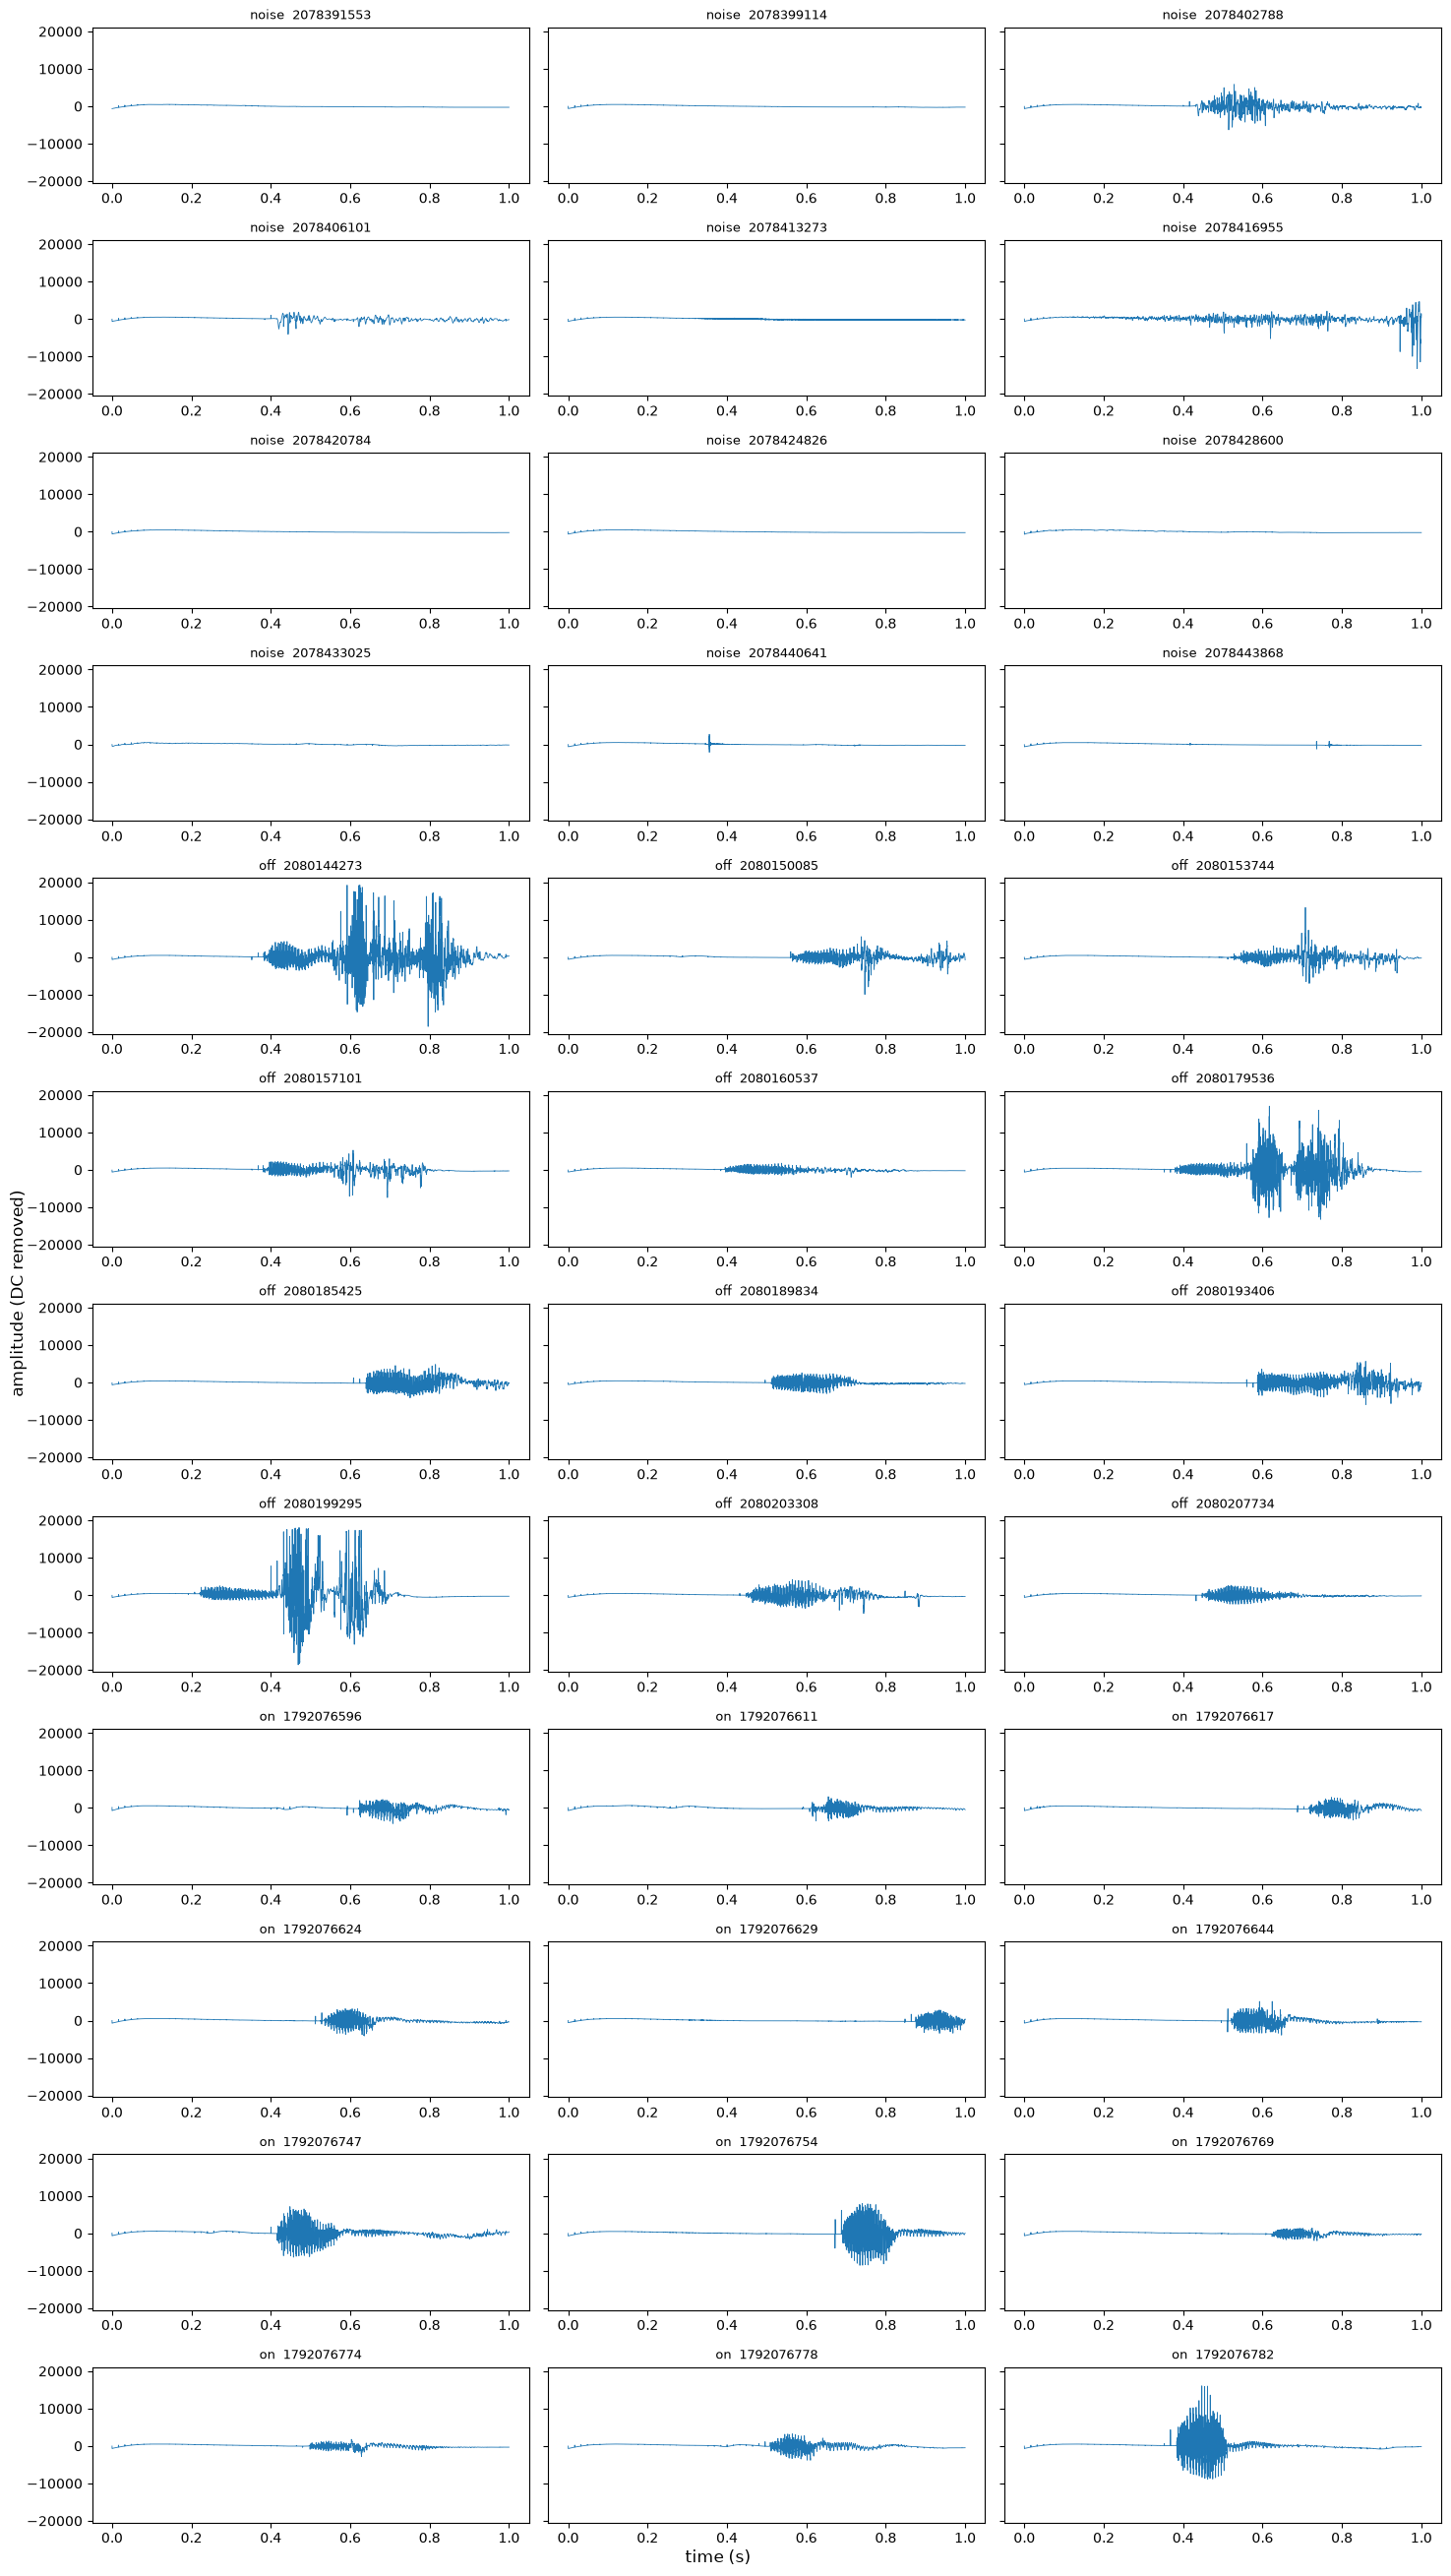

In [3]:
def grid(n):
    cols = 3; rows_ = int(np.ceil(n / cols)); return rows_, cols
SHOW = 12   # per-clip plots/players: first 12 clips per class (aggregate plots and the classifier use all clips)
all_clips = [(l, n, x) for l, items in clips.items() for n, x in items[:SHOW]]
r, c = grid(len(all_clips))
fig, axs = plt.subplots(r, c, figsize=(5 * c, 2.2 * r), sharey=True, squeeze=False)
t = np.arange(FS) / FS
for ax, (l, n, x) in zip(axs.flat, all_clips):
    ax.plot(t, x - x.mean(), lw=0.6); ax.set_title(f"{l}  {n[-14:-4]}", fontsize=9)
for ax in axs.flat[len(all_clips):]: ax.axis("off")
fig.supxlabel("time (s)"); fig.supylabel("amplitude (DC removed)"); fig.tight_layout()

## 3. Spectrograms
Time on x, frequency on y, colour = energy (dB). Vowels show as horizontal bands (formants); "f" / "s" show as a bright smear above ~3 kHz.

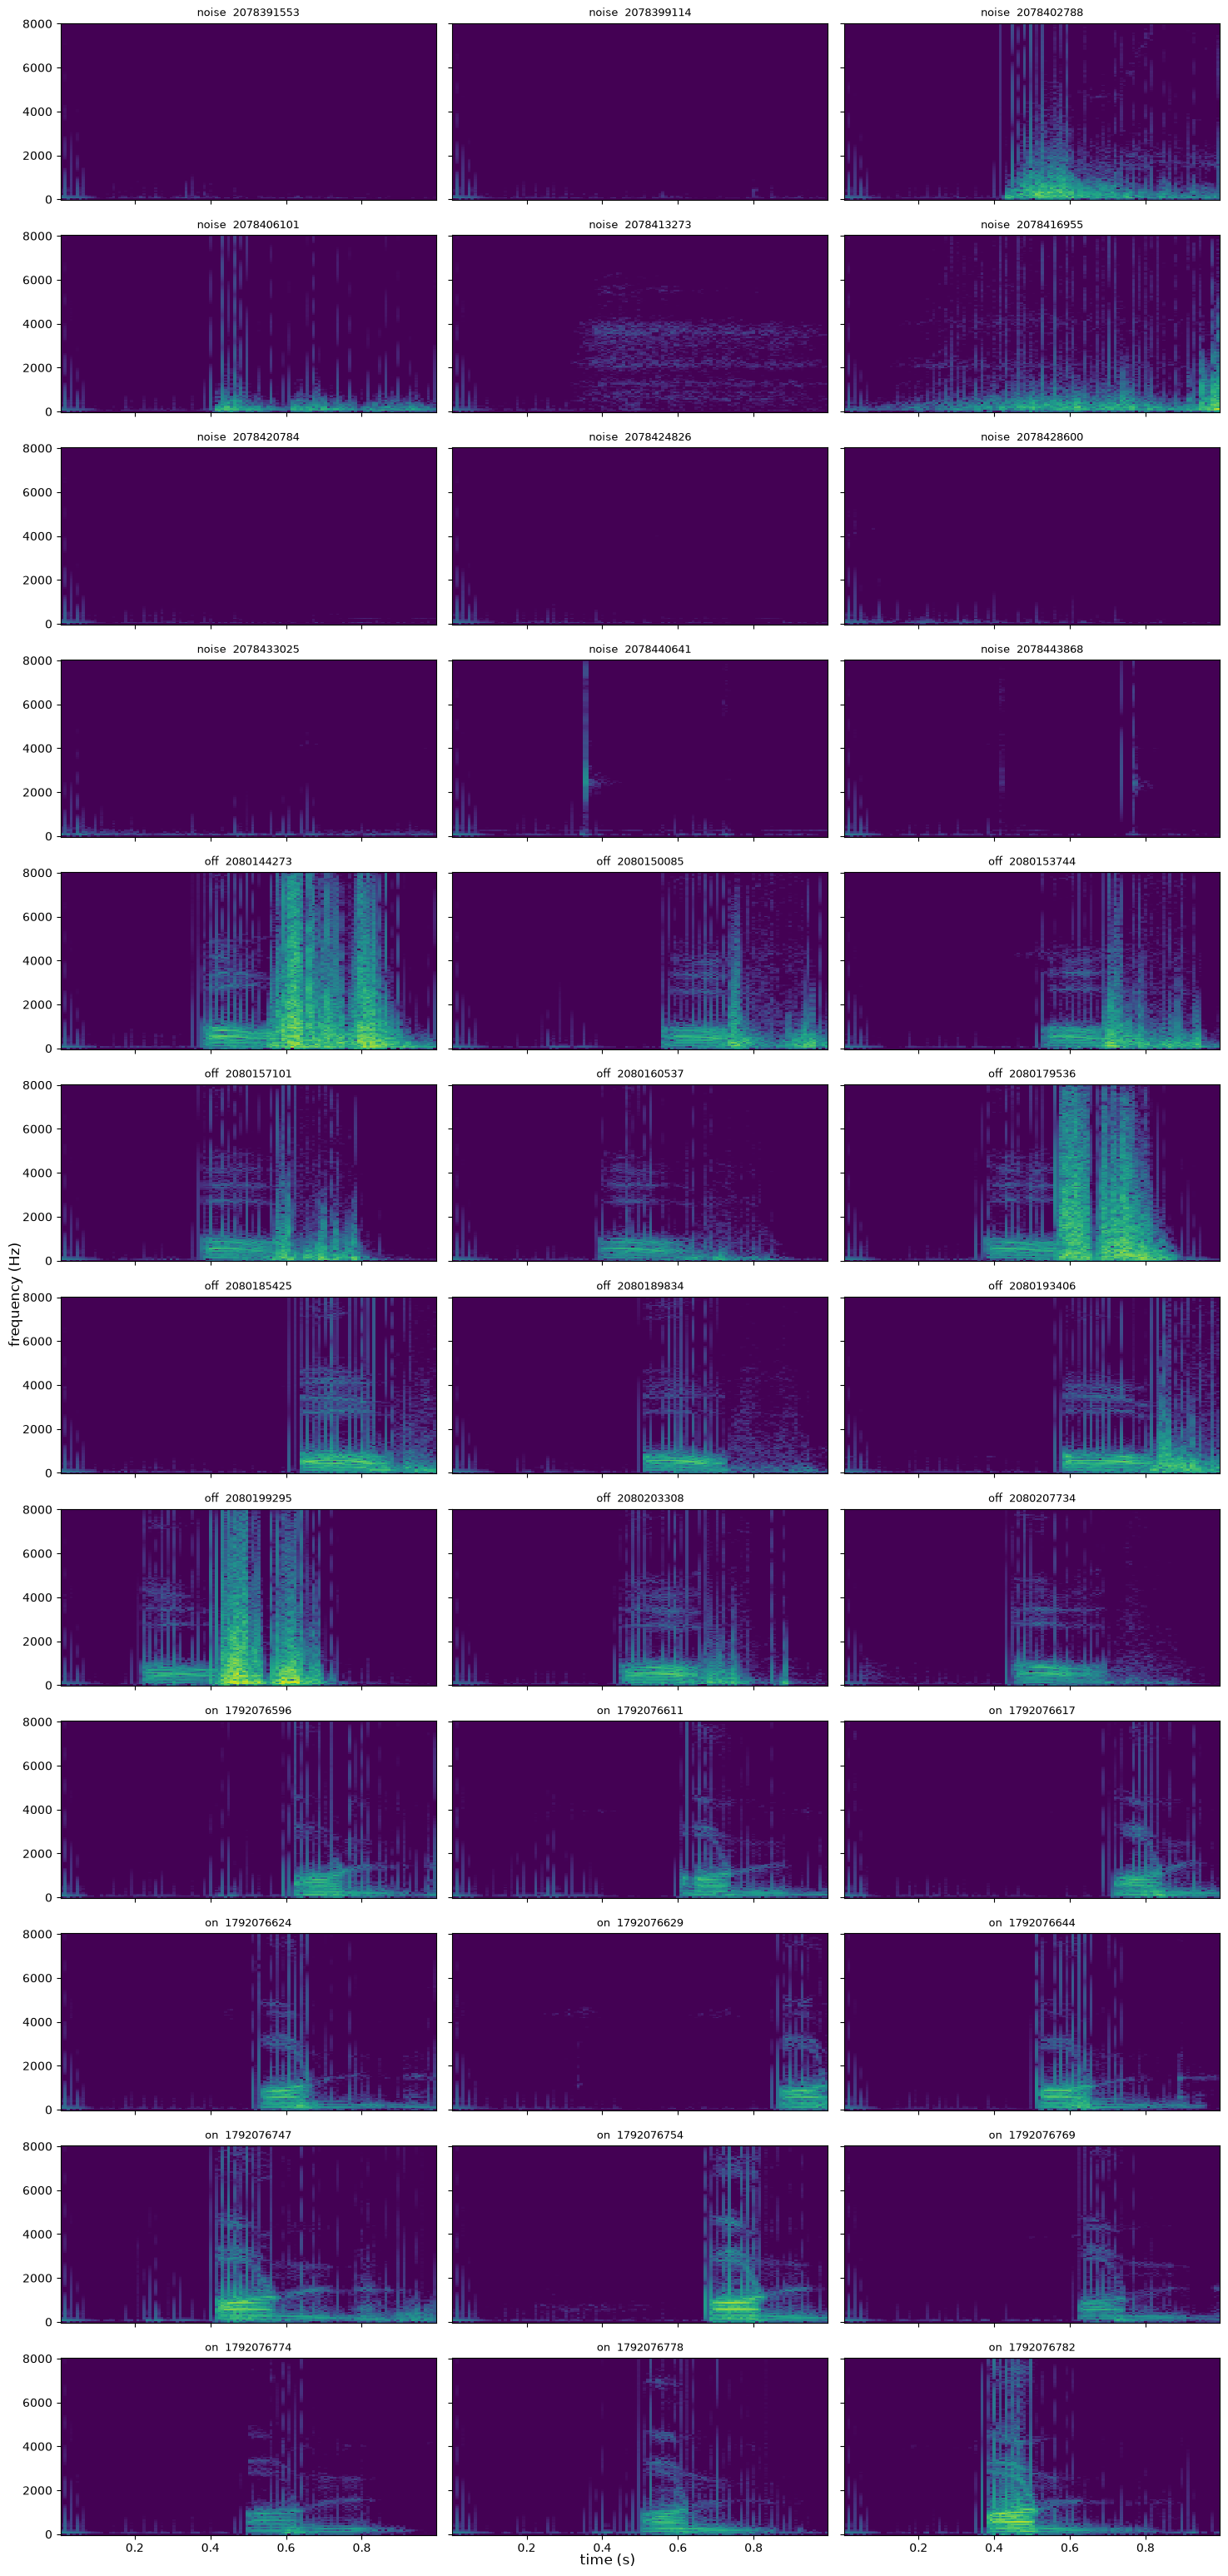

In [4]:
fig, axs = plt.subplots(r, c, figsize=(5 * c, 2.6 * r), sharex=True, sharey=True, squeeze=False)
for ax, (l, n, x) in zip(axs.flat, all_clips):
    f, tt, S = signal.spectrogram(x - x.mean(), FS, nperseg=256, noverlap=128)
    ax.pcolormesh(tt, f, 10 * np.log10(S + 1e-9), shading="auto", vmin=-10, vmax=60)
    ax.set_title(f"{l}  {n[-14:-4]}", fontsize=9)
for ax in axs.flat[len(all_clips):]: ax.axis("off")
fig.supxlabel("time (s)"); fig.supylabel("frequency (Hz)"); fig.tight_layout()

## 4. Average spectrum per label (Welch)
If the `on` and `off` curves separate somewhere, that frequency range is a usable DSP feature.

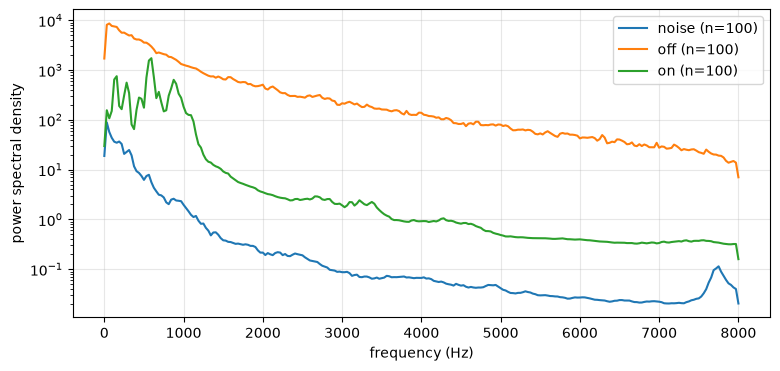

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, items in clips.items():
    P = np.mean([signal.welch(x - x.mean(), FS, nperseg=512)[1] for _, x in items], axis=0)
    ax.semilogy(signal.welch(items[0][1], FS, nperseg=512)[0], P, label=f"{label} (n={len(items)})")
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("power spectral density"); ax.legend(); ax.grid(alpha=0.3)

## 5. Band energies over time
The features the firmware would compute: energy in a few frequency bands per 16 ms frame.

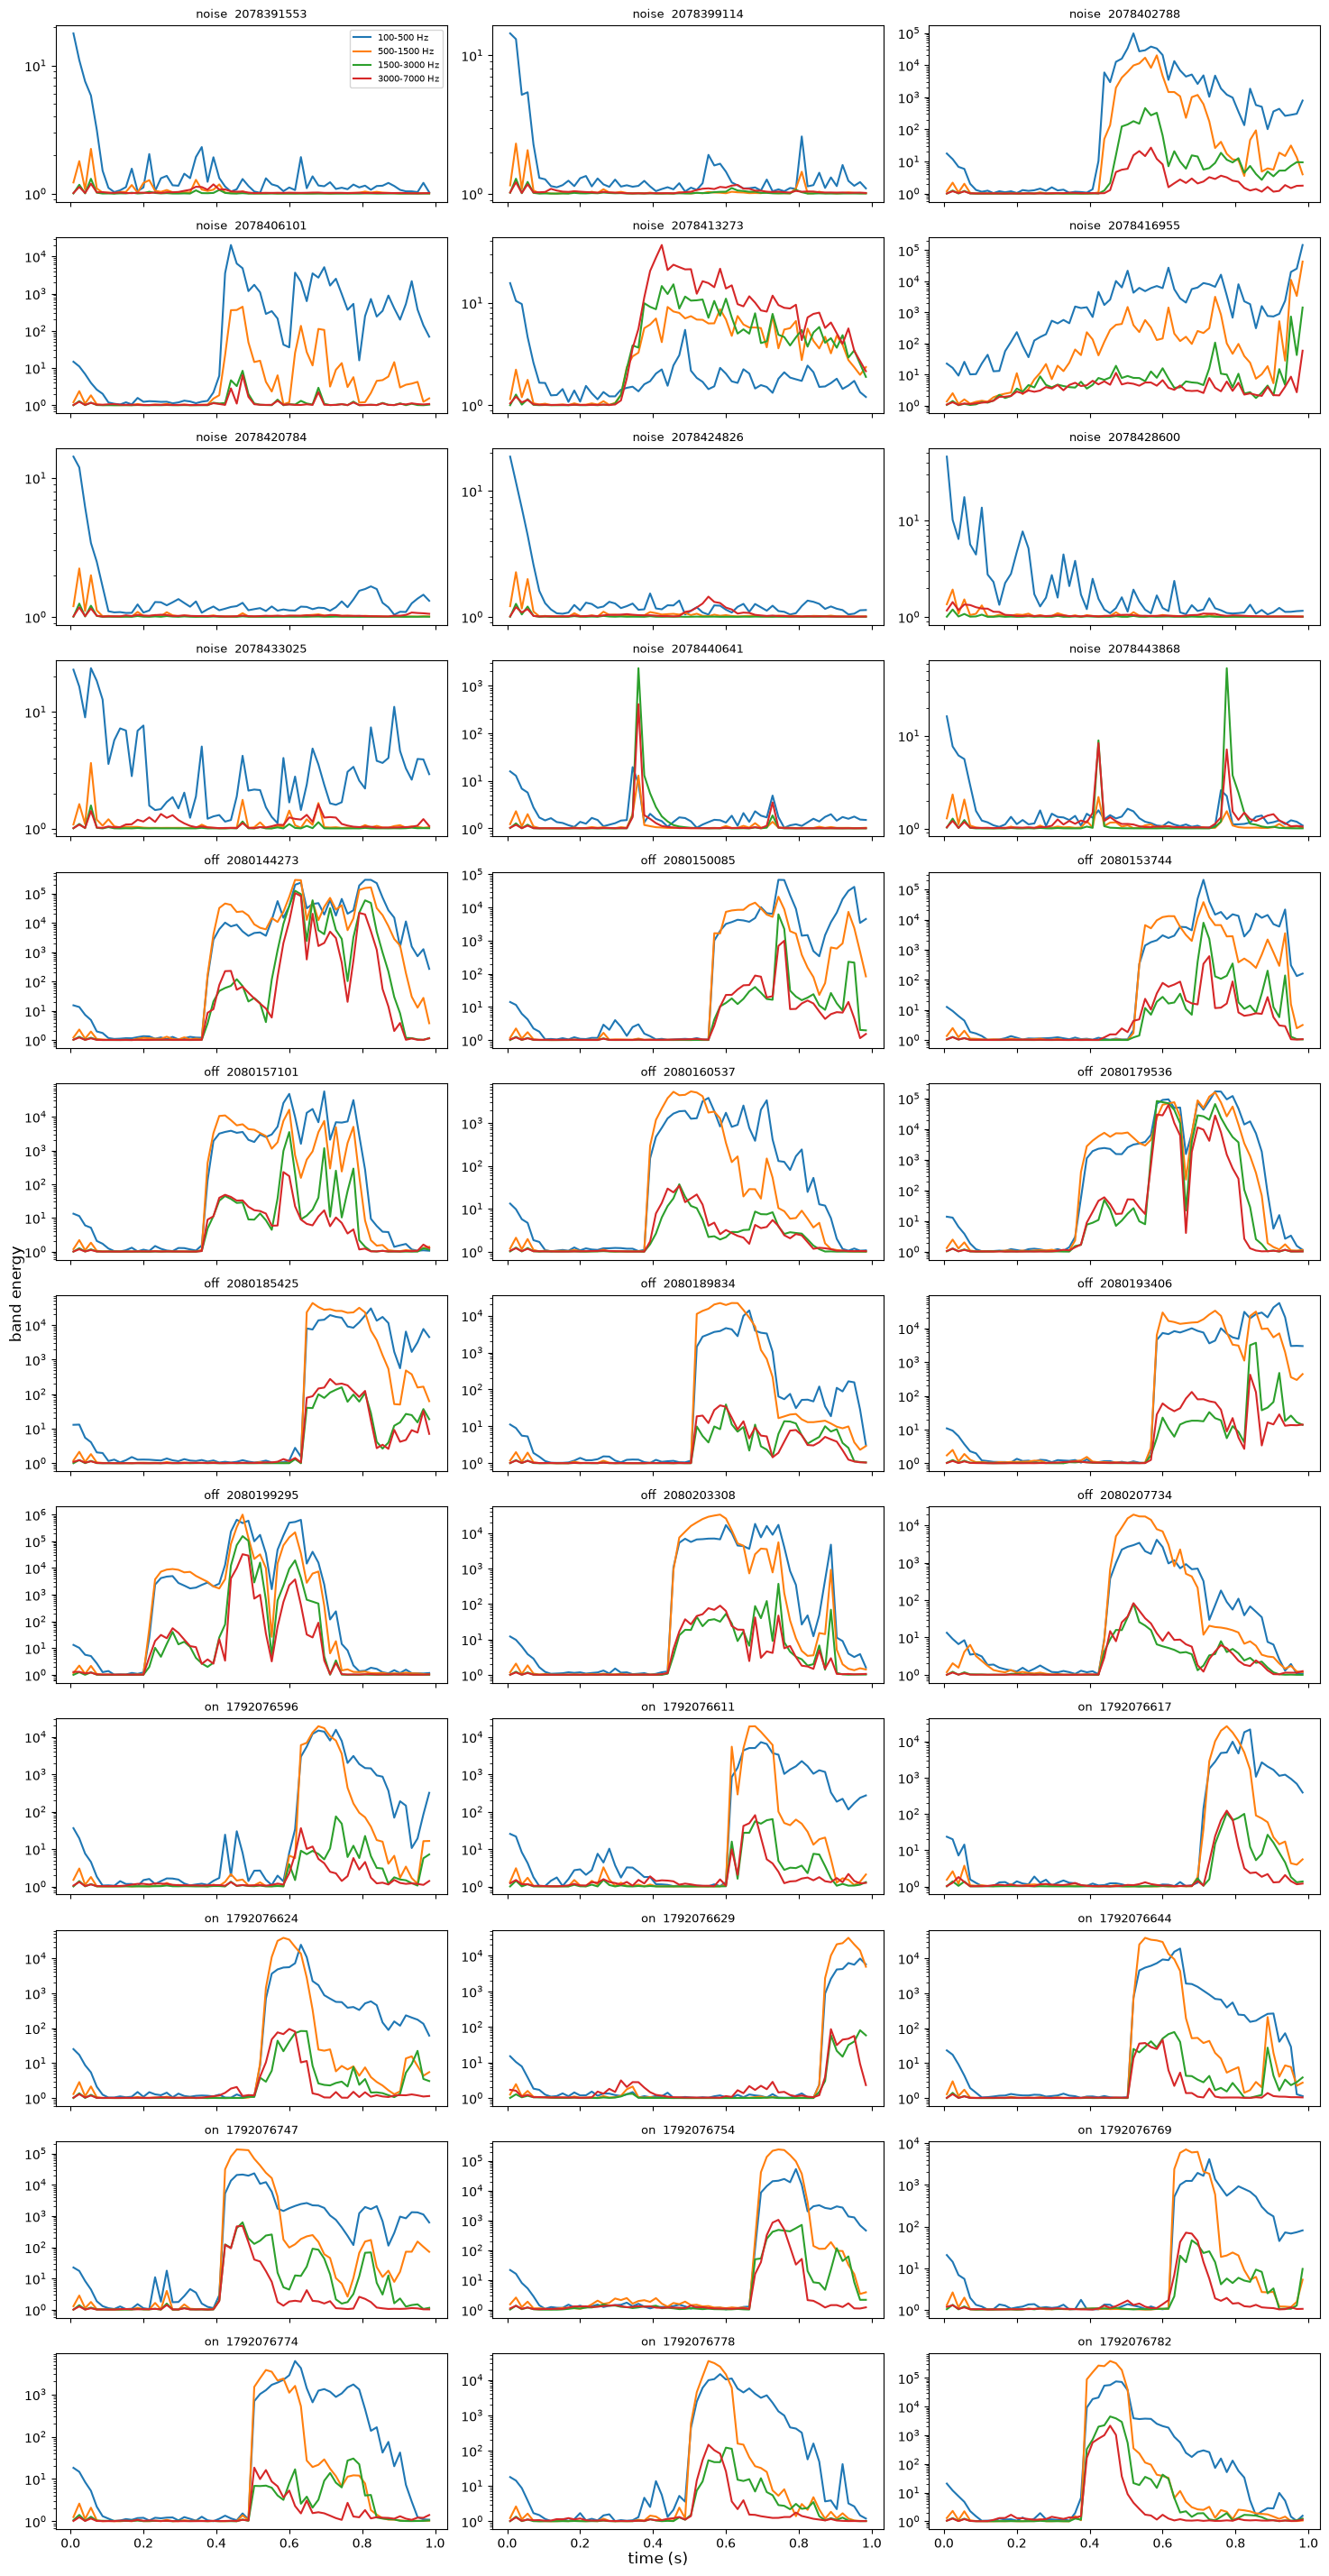

In [6]:
BANDS = [(100, 500), (500, 1500), (1500, 3000), (3000, 7000)]
def band_energy(x, nper=256):
    f, tt, S = signal.spectrogram(x - x.mean(), FS, nperseg=nper, noverlap=0)
    return tt, np.array([S[(f >= lo) & (f < hi)].sum(axis=0) for lo, hi in BANDS])

fig, axs = plt.subplots(r, c, figsize=(5 * c, 2.4 * r), sharex=True, squeeze=False)
for ax, (l, n, x) in zip(axs.flat, all_clips):
    tt, E = band_energy(x)
    for (lo, hi), e in zip(BANDS, E): ax.semilogy(tt, e + 1, label=f"{lo}-{hi} Hz")
    ax.set_title(f"{l}  {n[-14:-4]}", fontsize=9)
axs.flat[0].legend(fontsize=7)
for ax in axs.flat[len(all_clips):]: ax.axis("off")
fig.supxlabel("time (s)"); fig.supylabel("band energy"); fig.tight_layout()

## 6. Listen
Pick a clip to play in the notebook.

In [7]:
for l, n, x in all_clips:
    print(l, n); display(Audio(x - x.mean(), rate=FS))

noise noise_1792078391553.wav


noise noise_1792078399114.wav


noise noise_1792078402788.wav


noise noise_1792078406101.wav


noise noise_1792078413273.wav


...

on on_1792076754.wav


on on_1792076769.wav


on on_1792076774.wav


on on_1792076778.wav


on on_1792076782.wav


## 7. Does more data help? Accuracy vs number of recordings
**Score** = test accuracy: the fraction of clips classified correctly that the classifier has *never seen in training*. Chance with 3 classes is 33 %.

Method: in each of 40 repeats, hold out 20 random clips per class as the test set, then train on `n` random clips per class from the rest and measure test accuracy. The line is the mean over repeats; the shaded band is ±1 standard deviation (how much the result depends on which clips were picked).

Caveat: splits are random across clips, not across speakers. A test on a speaker the model has never heard will score lower.

In [8]:
FEATURE_NAMES = ["dur", "span", "peak_db", "b0", "b1", "b2", "b3", "cent", "hipos", "zcr", "crest"]

def features(x):
    x = x - x.mean()
    f, t, S = signal.spectrogram(x, FS, nperseg=256, noverlap=0)      # 16 ms frames
    db = 10 * np.log10(S.sum(0) + 1e-9)
    floor = np.percentile(db, 20)
    act = db > floor + 10                                              # frames 10 dB above the noise floor
    if act.sum() == 0: act[np.argmax(db)] = True
    idx = np.where(act)[0]
    Sa = S[:, act].sum(1); tot = Sa.sum() + 1e-9
    band = lambda lo, hi: Sa[(f >= lo) & (f < hi)].sum() / tot
    hi = S[f >= 3000].sum(0)
    span = max(idx[-1] - idx[0], 1)
    return [act.sum() * 0.016, (idx[-1] - idx[0] + 1) * 0.016, db.max() - floor,
            band(100, 500), band(500, 1500), band(1500, 3000), band(3000, 8000),
            (f * Sa).sum() / tot, (np.argmax(hi * act) - idx[0]) / span,
            np.mean(np.abs(np.diff(np.sign(x))) > 0), np.abs(x).max() / (x.std() + 1e-9)]

classes = sorted(clips)                                                # ['noise', 'off', 'on']
F = {c: np.array([features(x) for _, x in clips[c]]) for c in classes}
print({c: F[c].shape for c in classes})

{'noise': (100, 11), 'off': (100, 11), 'on': (100, 11)}


,loudness only / nearest centroid,bands + centroid / nearest centroid,bands + shape / nearest centroid,bands + shape / logistic regression
clips/class,,,,
3,69 +- 8,75 +- 9,80 +- 7,82 +- 7
5,71 +- 6,78 +- 5,83 +- 5,85 +- 4
8,71 +- 7,80 +- 4,85 +- 4,87 +- 4
10,72 +- 6,80 +- 4,86 +- 5,88 +- 4
15,72 +- 6,80 +- 4,86 +- 5,89 +- 3
20,73 +- 5,80 +- 4,86 +- 5,89 +- 3
30,73 +- 5,81 +- 5,86 +- 4,90 +- 3
40,73 +- 4,81 +- 5,86 +- 4,90 +- 3
50,73 +- 4,81 +- 5,86 +- 5,90 +- 3


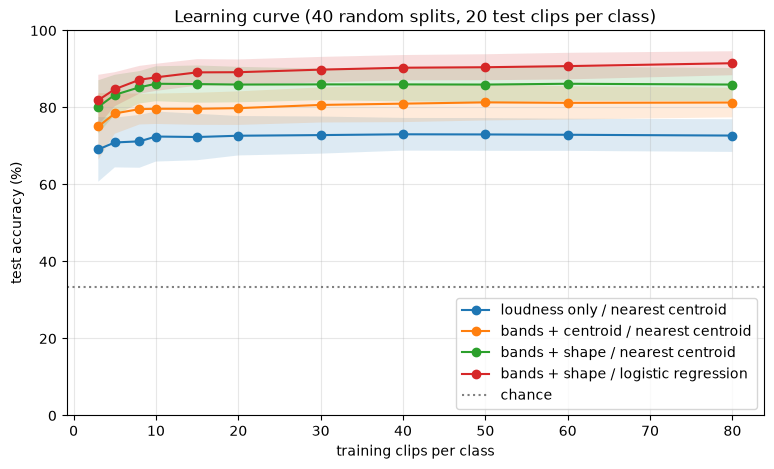

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestCentroid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

col = lambda *names: [FEATURE_NAMES.index(n) for n in names]
SETS = {"loudness only": col("peak_db"),
        "bands + centroid": col("b0", "b1", "b2", "b3", "cent"),
        "bands + shape": col("b0", "b1", "b2", "b3", "cent", "dur", "crest", "zcr", "hipos")}
MODELS = {"nearest centroid": lambda: make_pipeline(StandardScaler(), NearestCentroid()),
          "logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
CURVES = [("loudness only", "nearest centroid"), ("bands + centroid", "nearest centroid"),
          ("bands + shape", "nearest centroid"), ("bands + shape", "logistic regression")]

N_TEST, REPEATS = 20, 40
min_n = min(len(F[c]) for c in classes)
sizes = [n for n in (3, 5, 8, 10, 15, 20, 30, 40, 50, 60, 80, 100) if n <= min_n - N_TEST]
rng = np.random.default_rng(0)
acc = {k: np.zeros((REPEATS, len(sizes))) for k in CURVES}
for r in range(REPEATS):
    perm = {c: rng.permutation(len(F[c])) for c in classes}
    Xte = np.vstack([F[c][perm[c][:N_TEST]] for c in classes]); yte = np.repeat(classes, N_TEST)
    for j, n in enumerate(sizes):
        Xtr = np.vstack([F[c][perm[c][N_TEST:N_TEST + n]] for c in classes]); ytr = np.repeat(classes, n)
        for (fs, mn) in CURVES:
            m = MODELS[mn](); m.fit(Xtr[:, SETS[fs]], ytr)
            acc[(fs, mn)][r, j] = (m.predict(Xte[:, SETS[fs]]) == yte).mean()

fig, ax = plt.subplots(figsize=(9, 5))
for (fs, mn), a in acc.items():
    mean, sd = a.mean(0), a.std(0)
    ax.plot(sizes, mean * 100, marker="o", label=f"{fs} / {mn}")
    ax.fill_between(sizes, (mean - sd) * 100, (mean + sd) * 100, alpha=0.15)
ax.axhline(100 / len(classes), color="gray", ls=":", label="chance")
ax.set_xlabel("training clips per class"); ax.set_ylabel("test accuracy (%)")
ax.set_title(f"Learning curve ({REPEATS} random splits, {N_TEST} test clips per class)")
ax.set_ylim(0, 100); ax.grid(alpha=0.3); ax.legend(loc="lower right")
pd.DataFrame({f"{fs} / {mn}": [f"{m * 100:.0f} +- {s * 100:.0f}" for m, s in zip(a.mean(0), a.std(0))]
              for (fs, mn), a in acc.items()}, index=pd.Index(sizes, name="clips/class"))

**Reading the curve.** If a line is still climbing at the right edge, more recordings will help. If it has flattened, the limit is the features or the classifier, not the amount of data. A wide band means the score depends heavily on which clips happened to be in the training set.